In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

sns.set_theme(style="whitegrid", palette="viridis")

# Load dataset
df = pd.read_csv("../Ontrac_data.csv")

# Clean column names and categorical values
df.columns = df.columns.str.strip()

df["Client"] = df["Client"].astype("string").str.strip().str.upper()
df["Bank_Document"] = (
    df["Bank_Document"].astype("string").str.strip().str.upper()
)
df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")

# Keep records with the fields required for this analysis
df = df.dropna(subset=["Client", "Bank_Document", "Amount"])

print(df[["Client", "Bank_Document", "Amount"]].head())

                Client                     Bank_Document    Amount
0              NOVAQUA                 TRANSFER RECEIVED  21420.00
1   MY DE CONSTRUCTION  COLLECTION OF 1 BILL OF EXCHANGE  11144.00
2          TERRASTRUCT                 TRANSFER RECEIVED  36790.00
3  STE DERRAB LISSAKAN           OFF-BRANCH CASH DEPOSIT   4998.68
4  STE DERRAB LISSAKAN           OFF-BRANCH CASH DEPOSIT   4999.60


## 1. Which clients generate the highest total payment value through each bank-document type?

In [4]:
q1_stats = (
    df.groupby(["Client", "Bank_Document"])["Amount"]
      .agg(
          Total_Payment_Value="sum",
          Transaction_Count="count"
      )
      .reset_index()
      .sort_values("Total_Payment_Value", ascending=False)
)

q1_stats



,Client,Bank_Document,Total_Payment_Value,Transaction_Count
20,NOVAQUA,TRANSFER RECEIVED,839480.00,22
21,SCADACOM MAROC,TRANSFER RECEIVED,233610.00,6
5,ELIPROMO,TRANSFER RECEIVED,207435.00,5
15,MESWANE,TRANSFER RECEIVED,180167.00,5
2,AYOUB MARRAKECH,OFF-BRANCH CASH DEPOSIT,103042.79,23
23,STE ARAFIK,OFF-BRANCH CASH DEPOSIT,101331.04,27
31,STE RACHIDIA CARREAUX,COLLECTION OF 1 LCN,90400.00,2
27,STE DERRAB LISSAKAN,OFF-BRANCH CASH DEPOSIT,84295.24,17
30,STE OULAD ZAERS PROMO,TRANSFER RECEIVED,81675.00,2
19,NA MEGA S&C,TRANSFER RECEIVED,80460.00,2


## 2. Does a client's preferred payment method change according to transaction value?

In [6]:
q2_stats = df[["Client", "Bank_Document", "Amount"]].copy()

q2_stats["Transaction_Value_Group"] = pd.qcut(
    q2_stats["Amount"].rank(method="first"),
    q=3,
    labels=["Low", "Medium", "High"]
)

# Count transactions by client, method, and value group
q2_counts = (
    q2_stats.groupby(
        ["Client", "Transaction_Value_Group", "Bank_Document"],
        observed=False
    )
    .size()
    .reset_index(name="Transaction_Count")
)

# Identify the most frequently used method in each group
q2_preferred = q2_counts.loc[
    q2_counts.groupby(
        ["Client", "Transaction_Value_Group"],
        observed=False
    )["Transaction_Count"].idxmax()
].reset_index(drop=True)

print("Preferred payment method by client and transaction value:")
q2_preferred



Preferred payment method by client and transaction value:


,Client,Transaction_Value_Group,Bank_Document,Transaction_Count
0,AHMED AZIZI,Low,CHEQUE DEPOSITED FOR COLLECTION,0
1,AHMED AZIZI,Medium,COLLECTION OF 1 LCN,1
2,AHMED AZIZI,High,CHEQUE DEPOSITED FOR COLLECTION,0
3,AIT OUKHALI TRAVAUX,Low,CHEQUE DEPOSITED FOR COLLECTION,0
4,AIT OUKHALI TRAVAUX,Medium,TRANSFER RECEIVED,2
5,AIT OUKHALI TRAVAUX,High,CHEQUE DEPOSITED FOR COLLECTION,0
6,AYOUB MARRAKECH,Low,OFF-BRANCH CASH DEPOSIT,19
7,AYOUB MARRAKECH,Medium,OFF-BRANCH CASH DEPOSIT,4
8,AYOUB MARRAKECH,High,CHEQUE DEPOSITED FOR COLLECTION,0
9,DAIMON IMMO,Low,CHEQUE DEPOSITED FOR COLLECTION,0


#Interpretation: Compare payment-method shares between low-, medium-, and high-value transactions for each client. This reveals whether payment preferences differ with transaction size.

Note that the preferred method here means the most frequently used method, not necessarily the one with the highest monetary value.

## 3. Which clients have the highest average transaction value for cash deposits?

In [8]:
cash_df = df[
    df["Bank_Document"].str.contains("CASH DEPOSIT", na=False)
].copy()

q3_stats = (
    cash_df.groupby("Client")["Amount"]
           .agg(
               Average_Transaction="mean",
               Median_Transaction="median",
               Total_Payment_Value="sum",
               Transaction_Count="count"
           )
           .reset_index()
           .sort_values("Average_Transaction", ascending=False)
)

q3_stats

,Client,Average_Transaction,Median_Transaction,Total_Payment_Value,Transaction_Count
7,STE DERRAB LISSAKAN,4958.543529,4999.48,84295.24,17
0,AYOUB MARRAKECH,4480.121304,4550.72,103042.79,23
3,FAHMI ABDELJALIL (CIN WA77205),4413.210000,4413.21,4413.21,1
4,ISMANE DEVELOPPEMENT,4172.000000,4172.00,8344.00,2
5,STE ARAFIK,3753.001481,4320.00,101331.04,27
1,DISTRAC,3551.240000,4110.40,17756.20,5
2,FAHMI ABDELJALIL,3351.200000,3351.20,6702.40,2
6,STE ARAFIK (PROBABLE),3000.000000,3000.00,3000.00,1


#Interpretation: Clients with larger average cash deposit values may make larger individual payments. Check transaction counts as well, because an average based on one transaction may not represent a consistent pattern.

## 4. Which clients have the highest average transaction value for transfers?

In [9]:
transfer_df = df[
    df["Bank_Document"].str.contains("TRANSFER", na=False)
].copy()

q4_stats = (
    transfer_df.groupby("Client")["Amount"]
               .agg(
                   Average_Transaction="mean",
                   Median_Transaction="median",
                   Total_Payment_Value="sum",
                   Transaction_Count="count"
               )
               .reset_index()
               .sort_values("Average_Transaction", ascending=False)
)

q4_stats

,Client,Average_Transaction,Median_Transaction,Total_Payment_Value,Transaction_Count
12,STE AF.ED,48500.000000,48500.0,48500.0,1
2,ELIPROMO,41487.000000,41600.0,207435.0,5
15,STE OULAD ZAERS PROMO,40837.500000,40837.5,81675.0,2
1,DAIMON IMMO,40500.000000,40500.0,40500.0,1
7,MESTRACO,40230.000000,40230.0,40230.0,1
9,NA MEGA S&C,40230.000000,40230.0,80460.0,2
3,EMRAUDE PARK,40000.000000,40000.0,40000.0,1
11,SCADACOM MAROC,38935.000000,40515.0,233610.0,6
10,NOVAQUA,38158.181818,40230.0,839480.0,22
18,TERRASTRUCT,36790.000000,36790.0,36790.0,1


#Interpretation: This identifies clients with the largest average transfer values. Comparing average and median values helps reveal whether a few unusually large transactions are influencing the average.

## 5. Are particular clients associated with high-value transactions through specific payment methods?

In [10]:
threshold = df["Amount"].quantile(0.75)

df["High_Value"] = df["Amount"] > threshold

q5_stats = (
    df.groupby(["Client", "Bank_Document"])
      .agg(
          Transaction_Count=("Amount", "size"),
          High_Value_Count=("High_Value", "sum"),
          Total_Payment_Value=("Amount", "sum"),
          Average_Transaction=("Amount", "mean")
      )
      .reset_index()
)

q5_stats["High_Value_Percentage"] = (
    q5_stats["High_Value_Count"] /
    q5_stats["Transaction_Count"] * 100
)

q5_stats = q5_stats.sort_values(
    ["High_Value_Count", "High_Value_Percentage"],
    ascending=False
)

print("High-value threshold:", threshold)
q5_stats

High-value threshold: 40230.0


,Client,Bank_Document,Transaction_Count,High_Value_Count,Total_Payment_Value,Average_Transaction,High_Value_Percentage
20,NOVAQUA,TRANSFER RECEIVED,22,10,839480.00,38158.181818,45.454545
5,ELIPROMO,TRANSFER RECEIVED,5,4,207435.00,41487.000000,80.000000
15,MESWANE,TRANSFER RECEIVED,5,3,180167.00,36033.400000,60.000000
21,SCADACOM MAROC,TRANSFER RECEIVED,6,3,233610.00,38935.000000,50.000000
31,STE RACHIDIA CARREAUX,COLLECTION OF 1 LCN,2,2,90400.00,45200.000000,100.000000
3,DAIMON IMMO,TRANSFER RECEIVED,1,1,40500.00,40500.000000,100.000000
22,STE AF.ED,TRANSFER RECEIVED,1,1,48500.00,48500.000000,100.000000
30,STE OULAD ZAERS PROMO,TRANSFER RECEIVED,2,1,81675.00,40837.500000,50.000000
0,AHMED AZIZI,COLLECTION OF 1 LCN,1,0,24900.00,24900.000000,0.000000
1,AIT OUKHALI TRAVAUX,TRANSFER RECEIVED,2,0,26760.00,13380.000000,0.000000


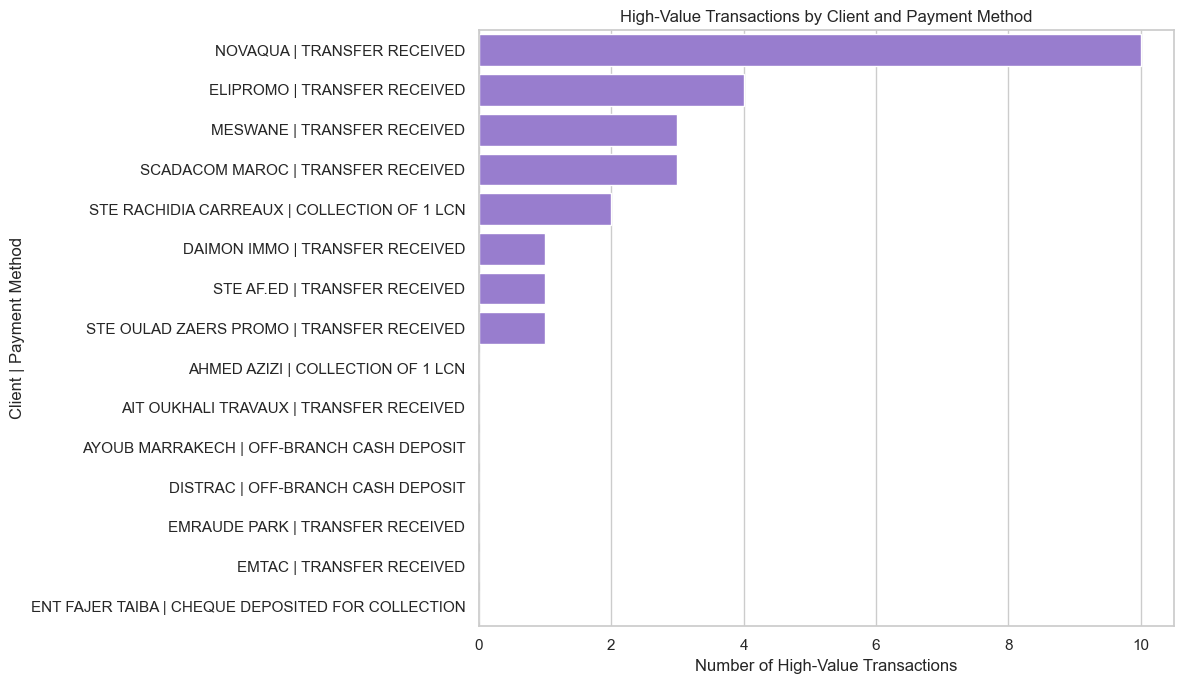

In [11]:
q5_plot = q5_stats.nlargest(15, "High_Value_Count").copy()

q5_plot["Combination"] = (
    q5_plot["Client"] + " | " + q5_plot["Bank_Document"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=q5_plot,
    x="High_Value_Count",
    y="Combination",
    color="mediumpurple"
)

plt.title("High-Value Transactions by Client and Payment Method")
plt.xlabel("Number of High-Value Transactions")
plt.ylabel("Client | Payment Method")
plt.tight_layout()
plt.show()

Interpretation: This identifies client–payment method combinations with the most high-value transactions. The percentage column helps distinguish combinations with frequent high-value transactions from those that simply have more transactions overall.

## 6. Which payment methods contribute the largest percentage of each client's total payment value?

In [12]:
q6_stats = (
    df.groupby(["Client", "Bank_Document"])["Amount"]
      .sum()
      .reset_index(name="Payment_Value")
)

q6_stats["Client_Total"] = (
    q6_stats.groupby("Client")["Payment_Value"].transform("sum")
)

q6_stats["Payment_Share_Percent"] = (
    q6_stats["Payment_Value"] / q6_stats["Client_Total"] * 100
)

q6_stats = q6_stats.sort_values(
    ["Client", "Payment_Share_Percent"],
    ascending=[True, False]
)

q6_stats

,Client,Bank_Document,Payment_Value,Client_Total,Payment_Share_Percent
0,AHMED AZIZI,COLLECTION OF 1 LCN,24900.00,24900.00,100.000000
1,AIT OUKHALI TRAVAUX,TRANSFER RECEIVED,26760.00,26760.00,100.000000
2,AYOUB MARRAKECH,OFF-BRANCH CASH DEPOSIT,103042.79,103042.79,100.000000
3,DAIMON IMMO,TRANSFER RECEIVED,40500.00,40500.00,100.000000
4,DISTRAC,OFF-BRANCH CASH DEPOSIT,17756.20,17756.20,100.000000
5,ELIPROMO,TRANSFER RECEIVED,207435.00,207435.00,100.000000
6,EMRAUDE PARK,TRANSFER RECEIVED,40000.00,40000.00,100.000000
7,EMTAC,TRANSFER RECEIVED,14239.00,14239.00,100.000000
8,ENT FAJER TAIBA,CHEQUE DEPOSITED FOR COLLECTION,54185.00,72515.00,74.722471
9,ENT FAJER TAIBA,TRANSFER RECEIVED,18330.00,72515.00,25.277529


In [13]:
# Dominant payment method for each client
q6_top = q6_stats.loc[
    q6_stats.groupby("Client")["Payment_Share_Percent"].idxmax()
]

print("\nDominant payment method by client:")
q6_top


Dominant payment method by client:


,Client,Bank_Document,Payment_Value,Client_Total,Payment_Share_Percent
0,AHMED AZIZI,COLLECTION OF 1 LCN,24900.00,24900.00,100.000000
1,AIT OUKHALI TRAVAUX,TRANSFER RECEIVED,26760.00,26760.00,100.000000
2,AYOUB MARRAKECH,OFF-BRANCH CASH DEPOSIT,103042.79,103042.79,100.000000
3,DAIMON IMMO,TRANSFER RECEIVED,40500.00,40500.00,100.000000
4,DISTRAC,OFF-BRANCH CASH DEPOSIT,17756.20,17756.20,100.000000
5,ELIPROMO,TRANSFER RECEIVED,207435.00,207435.00,100.000000
6,EMRAUDE PARK,TRANSFER RECEIVED,40000.00,40000.00,100.000000
7,EMTAC,TRANSFER RECEIVED,14239.00,14239.00,100.000000
8,ENT FAJER TAIBA,CHEQUE DEPOSITED FOR COLLECTION,54185.00,72515.00,74.722471
10,FAHMI ABDELJALIL,OFF-BRANCH CASH DEPOSIT,6702.40,6702.40,100.000000


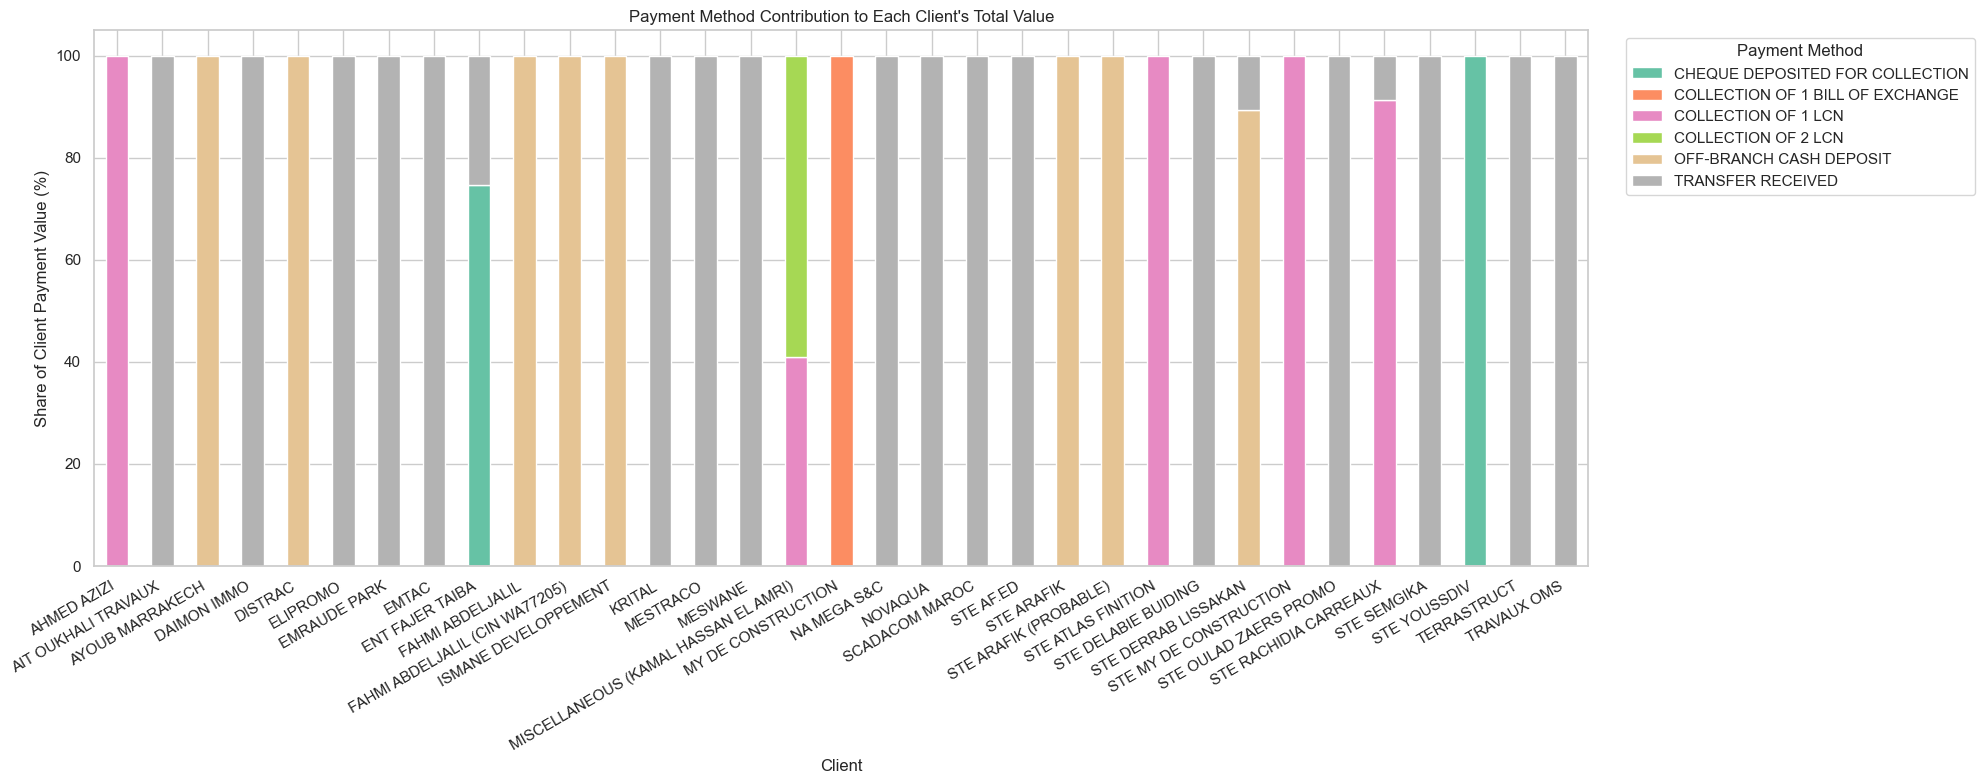

In [17]:
q6_pivot = q6_stats.pivot(
    index="Client",
    columns="Bank_Document",
    values="Payment_Share_Percent"
).fillna(0)

q6_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(20, 8),
    colormap="Set2"
)

plt.title("Payment Method Contribution to Each Client's Total Value")
plt.xlabel("Client")
plt.ylabel("Share of Client Payment Value (%)")
plt.legend(title="Payment Method", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

Interpretation: Each bar represents 100% of a client's payment value. The largest segment identifies the payment method contributing the most monetary value for that client.

## 7. Which clients rely most heavily on a particular payment method, and how concentrated is their payment activity?

In [18]:
q7_stats = (
    df.groupby(["Client", "Bank_Document"])["Amount"]
      .agg(
          Payment_Value="sum",
          Transaction_Count="count"
      )
      .reset_index()
)

q7_stats["Client_Total_Value"] = (
    q7_stats.groupby("Client")["Payment_Value"].transform("sum")
)

q7_stats["Value_Share_Percent"] = (
    q7_stats["Payment_Value"] / q7_stats["Client_Total_Value"] * 100
)

q7_stats["Client_Total_Transactions"] = (
    q7_stats.groupby("Client")["Transaction_Count"].transform("sum")
)

q7_stats["Transaction_Share_Percent"] = (
    q7_stats["Transaction_Count"] /
    q7_stats["Client_Total_Transactions"] * 100
)

# Find the dominant method by payment value for each client
q7_dominant = q7_stats.loc[
    q7_stats.groupby("Client")["Value_Share_Percent"].idxmax()
].sort_values("Value_Share_Percent", ascending=False)

q7_dominant

,Client,Bank_Document,Payment_Value,Transaction_Count,Client_Total_Value,Value_Share_Percent,Client_Total_Transactions,Transaction_Share_Percent
0,AHMED AZIZI,COLLECTION OF 1 LCN,24900.00,1,24900.00,100.000000,1,100.000000
1,AIT OUKHALI TRAVAUX,TRANSFER RECEIVED,26760.00,2,26760.00,100.000000,2,100.000000
2,AYOUB MARRAKECH,OFF-BRANCH CASH DEPOSIT,103042.79,23,103042.79,100.000000,23,100.000000
3,DAIMON IMMO,TRANSFER RECEIVED,40500.00,1,40500.00,100.000000,1,100.000000
4,DISTRAC,OFF-BRANCH CASH DEPOSIT,17756.20,5,17756.20,100.000000,5,100.000000
5,ELIPROMO,TRANSFER RECEIVED,207435.00,5,207435.00,100.000000,5,100.000000
6,EMRAUDE PARK,TRANSFER RECEIVED,40000.00,1,40000.00,100.000000,1,100.000000
7,EMTAC,TRANSFER RECEIVED,14239.00,1,14239.00,100.000000,1,100.000000
10,FAHMI ABDELJALIL,OFF-BRANCH CASH DEPOSIT,6702.40,2,6702.40,100.000000,2,100.000000
14,MESTRACO,TRANSFER RECEIVED,40230.00,1,40230.00,100.000000,1,100.000000


Interpretation: Clients toward the upper-right rely heavily on one payment method by both transaction count and payment value. This may signal operational dependence on a particular collection channel.

## 8. Which bank-document types have the highest average and median transaction values across clients?

In [20]:
q8_stats = (
    df.groupby("Bank_Document")["Amount"]
      .agg(
          Average_Transaction="mean",
          Median_Transaction="median",
          Total_Payment_Value="sum",
          Transaction_Count="count",
          Standard_Deviation="std"
      )
      .reset_index()
      .sort_values("Average_Transaction", ascending=False)
)

q8_stats

,Bank_Document,Average_Transaction,Median_Transaction,Total_Payment_Value,Transaction_Count,Standard_Deviation
5,TRANSFER RECEIVED,34921.241379,40230.00,2025432.00,58,10845.748932
2,COLLECTION OF 1 LCN,28879.333333,27938.00,173276.00,6,14341.040502
0,CHEQUE DEPOSITED FOR COLLECTION,24781.666667,22560.00,74345.00,3,6046.768421
3,COLLECTION OF 2 LCN,18000.000000,18000.00,18000.00,1,NaN
1,COLLECTION OF 1 BILL OF EXCHANGE,11144.000000,11144.00,11144.00,1,NaN
4,OFF-BRANCH CASH DEPOSIT,4216.472821,4550.72,328884.88,78,1009.730867


Interpretation: A large difference between the mean and median can indicate that a payment method has a few unusually large transactions. Transaction counts provide important context when comparing methods.

## 9. Which client–payment method combinations have the most transactions, and does transaction frequency correspond to higher total payment value?

In [21]:
q9_stats = (
    df.groupby(["Client", "Bank_Document"])["Amount"]
      .agg(
          Transaction_Count="count",
          Total_Payment_Value="sum",
          Average_Transaction="mean"
      )
      .reset_index()
      .sort_values("Transaction_Count", ascending=False)
)

q9_stats

,Client,Bank_Document,Transaction_Count,Total_Payment_Value,Average_Transaction
23,STE ARAFIK,OFF-BRANCH CASH DEPOSIT,27,101331.04,3753.001481
2,AYOUB MARRAKECH,OFF-BRANCH CASH DEPOSIT,23,103042.79,4480.121304
20,NOVAQUA,TRANSFER RECEIVED,22,839480.00,38158.181818
27,STE DERRAB LISSAKAN,OFF-BRANCH CASH DEPOSIT,17,84295.24,4958.543529
21,SCADACOM MAROC,TRANSFER RECEIVED,6,233610.00,38935.000000
15,MESWANE,TRANSFER RECEIVED,5,180167.00,36033.400000
5,ELIPROMO,TRANSFER RECEIVED,5,207435.00,41487.000000
4,DISTRAC,OFF-BRANCH CASH DEPOSIT,5,17756.20,3551.240000
1,AIT OUKHALI TRAVAUX,TRANSFER RECEIVED,2,26760.00,13380.000000
30,STE OULAD ZAERS PROMO,TRANSFER RECEIVED,2,81675.00,40837.500000


In [22]:
# Correlation between transaction count and total value
if len(q9_stats) >= 2:
    correlation = q9_stats[
        ["Transaction_Count", "Total_Payment_Value"]
    ].corr().iloc[0, 1]

    print("\nPearson correlation:", round(correlation, 3))
else:
    print("\nInsufficient combinations to calculate correlation.")


Pearson correlation: 0.566


C:\Users\prasa\AppData\Local\Temp\ipykernel_23260\1336772788.py:62: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


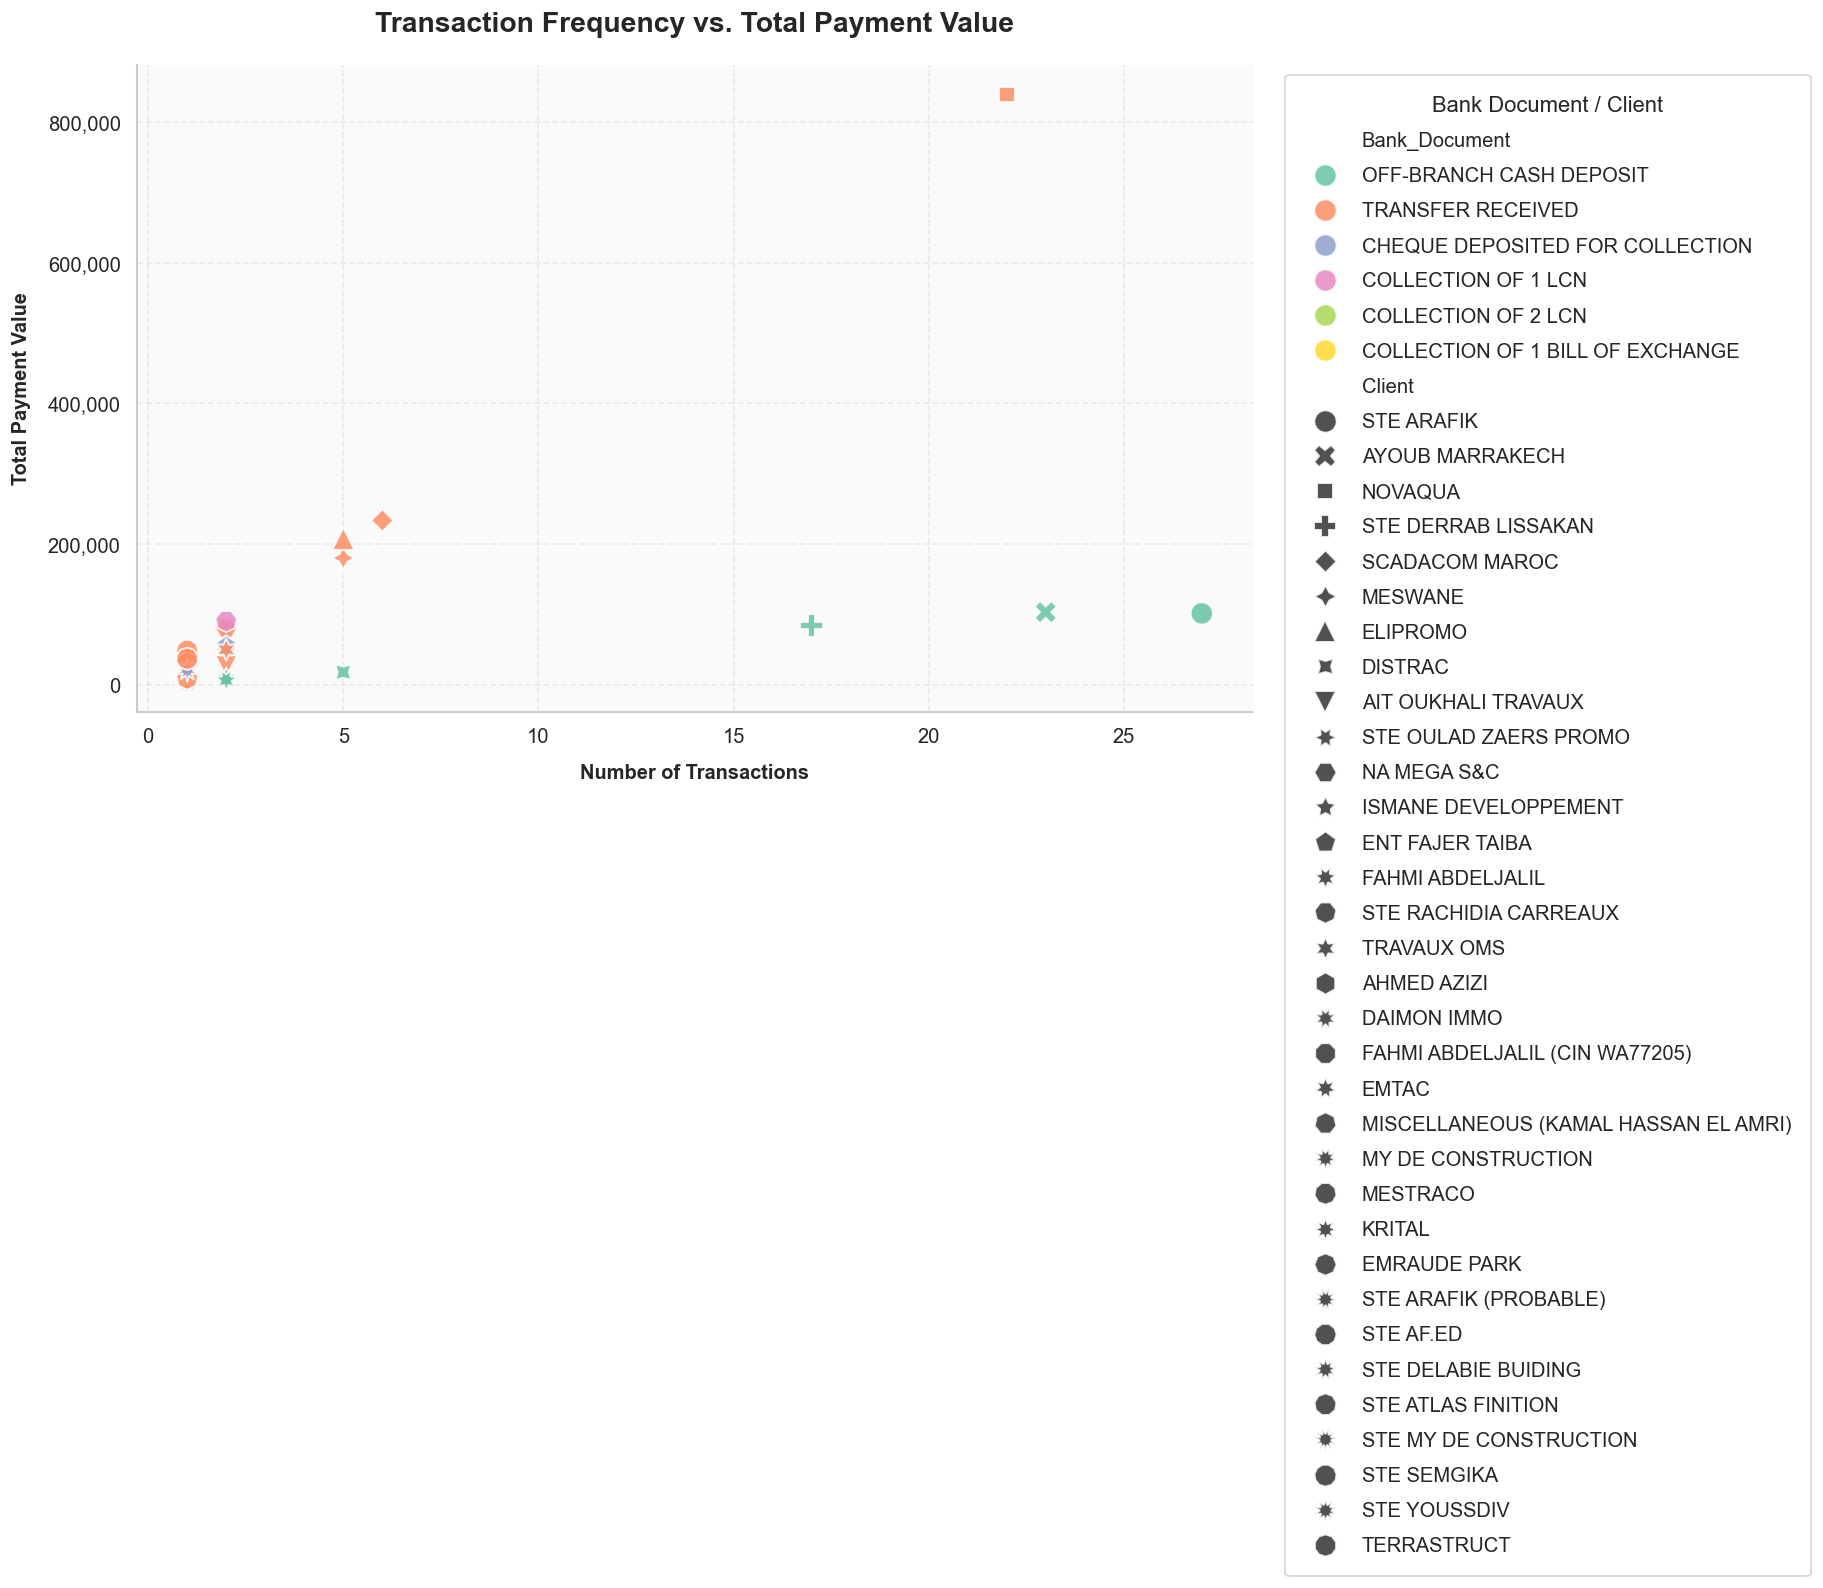

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Set a clean, professional theme
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

fig, ax = plt.subplots(figsize=(12, 7), dpi=120)

# Create scatter plot
sns.scatterplot(
    data=q9_stats,
    x="Transaction_Count",
    y="Total_Payment_Value",
    hue="Bank_Document",
    style="Client",
    palette="Set2",
    s=180,
    alpha=0.85,
    edgecolor="white",
    linewidth=1.2,
    ax=ax
)

# Improve title and axis labels
ax.set_title(
    "Transaction Frequency vs. Total Payment Value",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Number of Transactions", fontsize=12, fontweight="semibold", labelpad=10)
ax.set_ylabel("Total Payment Value", fontsize=12, fontweight="semibold", labelpad=10)

# Format large values with comma separators
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f"{x:,.0f}")
)

# Refine grid and borders
ax.grid(True, linestyle="--", alpha=0.35)
sns.despine(ax=ax, top=True, right=True)

# Improve legend placement
ax.legend(
    title="Bank Document / Client",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    borderpad=1,
    labelspacing=0.8
)

# Add subtle background
ax.set_facecolor("#FAFAFA")
fig.patch.set_facecolor("white")

plt.tight_layout()
plt.show()

Interpretation: Points farther right represent more frequent transactions, while points higher up represent greater total payment value. A positive correlation indicates that combinations with more transactions tend to have higher total values, though it does not establish causation.

## 10. Which client–payment method combinations show the greatest variability in transaction amounts, and which have the most consistent values?

In [26]:
q10_stats = (
    df.groupby(["Client", "Bank_Document"])["Amount"]
      .agg(
          Average_Transaction="mean",
          Median_Transaction="median",
          Standard_Deviation="std",
          Transaction_Count="count"
      )
      .reset_index()
)

q10_stats["CV_Percent"] = (
    q10_stats["Standard_Deviation"] /
    q10_stats["Average_Transaction"].abs() * 100
)

# At least two transactions are needed for variability analysis
q10_valid = q10_stats[
    (q10_stats["Transaction_Count"] >= 2) &
    (q10_stats["Average_Transaction"] != 0)
].copy()

q10_variable = q10_valid.nlargest(10, "Standard_Deviation")
q10_consistent = q10_valid.nsmallest(10, "CV_Percent")

print("Most variable combinations:")
q10_variable



Most variable combinations:


,Client,Bank_Document,Average_Transaction,Median_Transaction,Standard_Deviation,Transaction_Count,CV_Percent
15,MESWANE,TRANSFER RECEIVED,36033.400000,40345.0,10235.125930,5,28.404552
20,NOVAQUA,TRANSFER RECEIVED,38158.181818,40230.0,8518.829361,22,22.325040
8,ENT FAJER TAIBA,CHEQUE DEPOSITED FOR COLLECTION,27092.500000,27092.5,6409.922971,2,23.659400
21,SCADACOM MAROC,TRANSFER RECEIVED,38935.000000,40515.0,4398.594094,6,11.297275
36,TRAVAUX OMS,TRANSFER RECEIVED,24864.000000,24864.0,4388.304684,2,17.649231
1,AIT OUKHALI TRAVAUX,TRANSFER RECEIVED,13380.000000,13380.0,3931.513703,2,29.383510
23,STE ARAFIK,OFF-BRANCH CASH DEPOSIT,3753.001481,4320.0,1342.147293,27,35.761971
10,FAHMI ABDELJALIL,OFF-BRANCH CASH DEPOSIT,3351.200000,3351.2,1073.670937,2,32.038402
30,STE OULAD ZAERS PROMO,TRANSFER RECEIVED,40837.500000,40837.5,859.134739,2,2.103789
4,DISTRAC,OFF-BRANCH CASH DEPOSIT,3551.240000,4110.4,765.712379,5,21.561831


In [27]:
print("\nMost consistent combinations:")
q10_consistent


Most consistent combinations:


,Client,Bank_Document,Average_Transaction,Median_Transaction,Standard_Deviation,Transaction_Count,CV_Percent
19,NA MEGA S&C,TRANSFER RECEIVED,40230.000000,40230.00,0.000000,2,0.000000
31,STE RACHIDIA CARREAUX,COLLECTION OF 1 LCN,45200.000000,45200.00,565.685425,2,1.251516
5,ELIPROMO,TRANSFER RECEIVED,41487.000000,41600.00,757.937992,5,1.826929
30,STE OULAD ZAERS PROMO,TRANSFER RECEIVED,40837.500000,40837.50,859.134739,2,2.103789
27,STE DERRAB LISSAKAN,OFF-BRANCH CASH DEPOSIT,4958.543529,4999.48,168.239743,17,3.392927
12,ISMANE DEVELOPPEMENT,OFF-BRANCH CASH DEPOSIT,4172.000000,4172.00,362.038672,2,8.677821
2,AYOUB MARRAKECH,OFF-BRANCH CASH DEPOSIT,4480.121304,4550.72,504.350268,23,11.257514
21,SCADACOM MAROC,TRANSFER RECEIVED,38935.000000,40515.00,4398.594094,6,11.297275
36,TRAVAUX OMS,TRANSFER RECEIVED,24864.000000,24864.00,4388.304684,2,17.649231
4,DISTRAC,OFF-BRANCH CASH DEPOSIT,3551.240000,4110.40,765.712379,5,21.561831


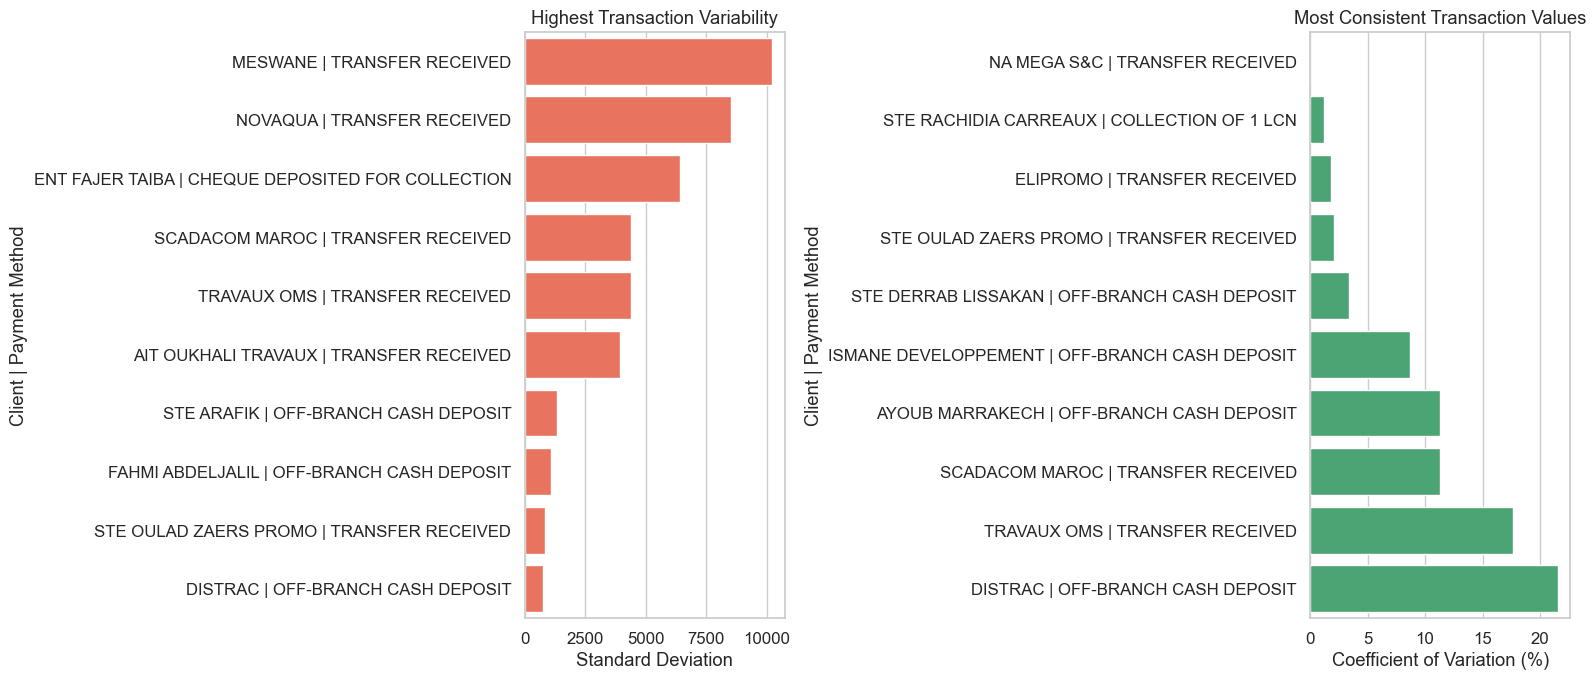

In [28]:
q10_variable = q10_variable.copy()
q10_consistent = q10_consistent.copy()

q10_variable["Combination"] = (
    q10_variable["Client"] + " | " + q10_variable["Bank_Document"]
)

q10_consistent["Combination"] = (
    q10_consistent["Client"] + " | " + q10_consistent["Bank_Document"]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=q10_variable,
    x="Standard_Deviation",
    y="Combination",
    ax=axes[0],
    color="tomato"
)

axes[0].set_title("Highest Transaction Variability")
axes[0].set_xlabel("Standard Deviation")
axes[0].set_ylabel("Client | Payment Method")

sns.barplot(
    data=q10_consistent,
    x="CV_Percent",
    y="Combination",
    ax=axes[1],
    color="mediumseagreen"
)

axes[1].set_title("Most Consistent Transaction Values")
axes[1].set_xlabel("Coefficient of Variation (%)")
axes[1].set_ylabel("Client | Payment Method")

plt.tight_layout()
plt.show()

Interpretation: High standard deviation indicates large absolute differences in transaction values. Low CV indicates more consistent values relative to the average. Combinations with fewer than two transactions are excluded because their variability cannot be estimated reliably.